<a href="https://colab.research.google.com/github/melissa-04/spink1-gbm-hypoxia/blob/main/06_cgga_replication.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 06 Replication in CGGA cohorts

Replicates the SPINK1-hypoxia association in two independent cohorts from the Chinese Glioma Genome Atlas (mRNAseq_693 and mRNAseq_325). Cohorts include primary WHO grade IV glioblastomas without a reported IDH mutation; samples with missing IDH status are kept (7 in mRNAseq_693). Read counts are normalized to log2(CPM+1). Produces Tables S12-S15 and Figure 4.

In [1]:
%%capture
!pip install -q gseapy

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys, zipfile
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

BASE = '/content/drive/MyDrive/SPINK1'
REPO = os.path.join(BASE, 'repo')
RESULTS = os.path.join(REPO, 'results')
sys.path.append(REPO)
from spink1_utils import (MYELOID, MES_CLEAN, GROUP_ORDER, hallmark_sets, proliferation_genes,
                          panel_score, partial_spearman, spink1_groups)

def extract(name):
    with zipfile.ZipFile(os.path.join(BASE, name)) as z:
        member = [m for m in z.namelist() if m.endswith('.txt') and not m.startswith('__MACOSX')][0]
        return z.extract(member, '/content/cgga')

FILES = {}
for tag in ['693', '325']:
    FILES['clinical', tag] = extract(f'CGGA.mRNAseq_{tag}_clinical.20200506.txt.zip')
    FILES['counts', tag] = extract(f'CGGA.mRNAseq_{tag}.Read_Counts-genes.20220620.txt.zip')

lib = hallmark_sets()
HYPOXIA = lib['Hypoxia']
PANELS = {'Hypoxia': HYPOXIA, 'Myeloid': MYELOID, 'Mes_clean': MES_CLEAN,
          'Proliferation': proliferation_genes(lib)}

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
def build_cohort(tag):
    clin = pd.read_csv(FILES['clinical', tag], sep='\t')
    clin.columns = clin.columns.str.strip()
    sequenced = pd.read_csv(FILES['counts', tag], sep='\t', nrows=0).columns
    keep = (clin['CGGA_ID'].isin(sequenced) & (clin['PRS_type'] == 'Primary') &
            (clin['Grade'] == 'WHO IV') & (clin['Histology'] == 'GBM') &
            (clin['IDH_mutation_status'] != 'Mutant'))
    return clin[keep].reset_index(drop=True)

cohorts = {tag: build_cohort(tag) for tag in ['693', '325']}
for tag, c in cohorts.items():
    print(f'CGGA-{tag}: n = {len(c)} |', c['IDH_mutation_status'].fillna('Not available').value_counts().to_dict())
print('Shared patients:', len(set(cohorts['693']['CGGA_ID']) & set(cohorts['325']['CGGA_ID'])))

CGGA-693: n = 116 | {'Wildtype': 109, 'Not available': 7}
CGGA-325: n = 74 | {'Wildtype': 74}
Shared patients: 0


In [4]:
def build_expression(tag, ids):
    raw = pd.read_csv(FILES['counts', tag], sep='\t', low_memory=False)
    gene = raw.columns[0]
    raw = raw[raw[gene].notna()].set_index(gene)
    counts = raw[ids].apply(pd.to_numeric, errors='coerce')
    counts['mean_count'] = counts.mean(axis=1)
    counts = counts.sort_values('mean_count', ascending=False)
    counts = counts[~counts.index.duplicated()].drop(columns='mean_count')

    cpm = counts / counts.sum() * 1e6
    log_cpm = np.log2(cpm + 1)
    expressed = (cpm > 1).sum(axis=1) >= 0.2 * len(ids)
    print(f'CGGA-{tag}: {int(expressed.sum())} expressed genes | SPINK1 passes filter: {expressed["SPINK1"]}')
    L = log_cpm[expressed]
    if not expressed['SPINK1']:
        L = pd.concat([L, log_cpm.loc[['SPINK1']]])
    return L

data = {}
for tag, c in cohorts.items():
    L = build_expression(tag, list(c['CGGA_ID']))
    S = pd.DataFrame({'SPINK1': L.loc['SPINK1']})
    for name, genes in PANELS.items():
        S[name] = panel_score(L, genes)
    S['group'] = spink1_groups(S['SPINK1'])
    data[tag] = (L, S)
    print('  genes per panel:', {k: f'{sum(g in L.index for g in v)}/{len(v)}' for k, v in PANELS.items()})
    print('  SPINK1 groups:', S['group'].value_counts().reindex(GROUP_ORDER).to_dict())

CGGA-693: 17895 expressed genes | SPINK1 passes filter: False
  genes per panel: {'Hypoxia': '178/200', 'Myeloid': '9/11', 'Mes_clean': '10/10', 'Proliferation': '311/327'}
  SPINK1 groups: {'Undetectable': 29, 'Low': 44, 'High': 43}
CGGA-325: 18004 expressed genes | SPINK1 passes filter: True
  genes per panel: {'Hypoxia': '177/200', 'Myeloid': '9/11', 'Mes_clean': '10/10', 'Proliferation': '311/327'}
  SPINK1 groups: {'Undetectable': 16, 'Low': 29, 'High': 29}


In [5]:
rows = []
for tag, (L, S) in data.items():
    r0, p0 = spearmanr(S['SPINK1'], S['Hypoxia'])
    r1, p1 = partial_spearman(S['SPINK1'], S['Hypoxia'], S[['Myeloid', 'Mes_clean', 'Proliferation']])
    det = S[S['SPINK1'] > 0]
    r2, p2 = spearmanr(det['SPINK1'], det['Hypoxia'])
    rows.append({'cohort': f'CGGA_{tag}', 'n': len(S), 'rho_raw': round(r0, 3), 'p_raw': f'{p0:.2e}',
                 'rho_full_adj': round(r1, 3), 'p_adj': f'{p1:.4f}', 'n_detectable': len(det),
                 'rho_detectable': round(r2, 3), 'p_det': f'{p2:.4f}'})

s12 = pd.DataFrame(rows)
s12.to_csv(os.path.join(RESULTS, 'Table_S12_CGGA_replication.csv'), index=False)
print(s12.to_string(index=False))

  cohort   n  rho_raw    p_raw  rho_full_adj  p_adj  n_detectable  rho_detectable  p_det
CGGA_693 116    0.586 4.83e-12         0.211 0.0252            87           0.573 0.0000
CGGA_325  74    0.634 1.34e-09         0.448 0.0001            58           0.619 0.0000


In [11]:
s4 = pd.read_csv(os.path.join(RESULTS, 'Table_S4_SPINK1_genomewide_correlation.csv'))
s13 = (s4[s4['gene'].isin(HYPOXIA)].set_index('gene')[['rho', 'FDR_q']]
       .rename(columns={'rho': 'TCGA', 'FDR_q': 'TCGA_FDR'}))
for tag, (L, S) in data.items():
    rho = {g: spearmanr(S['SPINK1'], L.loc[g])[0] for g in HYPOXIA if g in L.index}
    s13 = s13.join(pd.Series(rho, name=f'CGGA_{tag}'), how='inner')
s13 = s13.dropna()

COHORTS = ['TCGA', 'CGGA_693', 'CGGA_325']
s13['mean_rho'] = s13[COHORTS].mean(axis=1)
s13['pos_in_all'] = (s13[COHORTS] > 0).all(axis=1)
s13 = s13.sort_values('mean_rho', ascending=False).rename_axis('gene').reset_index()
s13.to_csv(os.path.join(RESULTS, 'Table_S13_hypoxia_genes_three_cohorts.csv'), index=False)

print('Genes in all three cohorts:', len(s13))
for a, b in [('TCGA', 'CGGA_693'), ('TCGA', 'CGGA_325'), ('CGGA_693', 'CGGA_325')]:
    r, p = spearmanr(s13[a], s13[b])
    print(f'{a} vs {b}: rho = {r:.3f}, p = {p:.2e}')
sig = s13[s13['TCGA_FDR'] < 0.05]
print(f'Positive in all three: {s13["pos_in_all"].sum()} of {len(s13)}')
print(f'TCGA FDR < 0.05: {len(sig)} genes, positive in all three: {sig["pos_in_all"].sum()} '
      f'({sig["pos_in_all"].mean():.0%})')

Genes in all three cohorts: 176
TCGA vs CGGA_693: rho = 0.652, p = 1.18e-22
TCGA vs CGGA_325: rho = 0.861, p = 4.91e-53
CGGA_693 vs CGGA_325: rho = 0.730, p = 1.51e-30
Positive in all three: 130 of 176
TCGA FDR < 0.05: 89 genes, positive in all three: 81 (91%)


In [7]:
CONTROLS = [
    ('CA9', 'Hypoxia', 'positive (canonical HIF target)'),
    ('VEGFA', 'Hypoxia', 'positive (HIF target)'),
    ('ADM', 'Hypoxia', 'positive (HIF target)'),
    ('PTPRC', 'Myeloid', 'positive (CD45, pan-leukocyte)'),
    ('CD68', 'Myeloid', 'positive (macrophage)'),
    ('MKI67', 'Proliferation', 'positive (Ki-67)'),
    ('TOP2A', 'Proliferation', 'positive'),
    ('CHI3L1', 'Mesenchymal', 'positive (YKL-40)'),
    ('SNAP25', 'Hypoxia', 'NEGATIVE (neuronal)'),
    ('SYT1', 'Hypoxia', 'NEGATIVE (neuronal)'),
    ('RBFOX3', 'Hypoxia', 'NEGATIVE (neuronal)'),
    ('SPINK1', 'Hypoxia', 'test gene'),
]
CONTROL_PANELS = {**PANELS, 'Mesenchymal': MES_CLEAN}

rows = []
for gene, panel, expectation in CONTROLS:
    row = {'gene': gene, 'panel': panel, 'expectation': expectation}
    for tag, (L, S) in data.items():
        if gene not in L.index:
            row[f'CGGA_{tag}'] = 'absent'
            continue
        r, p = spearmanr(L.loc[gene], panel_score(L, CONTROL_PANELS[panel], drop=gene))
        row[f'CGGA_{tag}'] = f'{r:.3f}' + ('*' if p < 0.05 else '')
    rows.append(row)

s14 = pd.DataFrame(rows)
s14.to_csv(os.path.join(RESULTS, 'Table_S14_pipeline_controls.csv'), index=False)
print(s14.to_string(index=False))

  gene         panel                     expectation CGGA_693 CGGA_325
   CA9       Hypoxia positive (canonical HIF target)   0.675*   0.745*
 VEGFA       Hypoxia           positive (HIF target)   0.642*   0.661*
   ADM       Hypoxia           positive (HIF target)   0.643*   0.691*
 PTPRC       Myeloid  positive (CD45, pan-leukocyte)   0.673*   0.779*
  CD68       Myeloid           positive (macrophage)   absent   absent
 MKI67 Proliferation                positive (Ki-67)   0.848*   0.836*
 TOP2A Proliferation                        positive   0.930*   0.929*
CHI3L1   Mesenchymal               positive (YKL-40)   0.725*   0.617*
SNAP25       Hypoxia             NEGATIVE (neuronal)    0.161  -0.262*
  SYT1       Hypoxia             NEGATIVE (neuronal)    0.064  -0.402*
RBFOX3       Hypoxia             NEGATIVE (neuronal)    0.080  -0.266*
SPINK1       Hypoxia                       test gene   0.586*   0.634*


In [8]:
rng = np.random.default_rng(42)
rows = []
for tag, (L, S) in data.items():
    hyp_in = [g for g in HYPOXIA if g in L.index]
    hyp_set = set(hyp_in)
    pool = [g for g in L.index if g not in hyp_set]
    for gene in ['SPINK1', 'CA9', 'SNAP25']:
        x = L.loc[gene]
        obs = spearmanr(x, panel_score(L, hyp_in, drop=gene))[0]
        null = []
        for _ in range(1000):
            genes = [g for g in rng.choice(pool, len(hyp_in), replace=False) if g != gene]
            r = spearmanr(x, panel_score(L, genes))[0]
            if np.isfinite(r):
                null.append(r)
        null = np.array(null)
        p_emp = (np.abs(null) >= abs(obs)).mean()
        rows.append({'cohort': f'CGGA_{tag}', 'gene': gene, 'rho_hypoxia': round(obs, 3),
                     'null_mean': round(null.mean(), 3), 'null_sd': round(null.std(), 3),
                     'null_95pct': round(np.percentile(np.abs(null), 95), 3),
                     'z_score': round((obs - null.mean()) / null.std(), 2),
                     'p_empirical': '<0.001' if p_emp == 0 else f'{p_emp:.3f}'})

s15 = pd.DataFrame(rows)
s15.to_csv(os.path.join(RESULTS, 'Table_S15_specificity_null.csv'), index=False)
print(s15.to_string(index=False))

  cohort   gene  rho_hypoxia  null_mean  null_sd  null_95pct  z_score p_empirical
CGGA_693 SPINK1        0.586      0.238    0.035       0.295    10.04      <0.001
CGGA_693    CA9        0.675      0.272    0.051       0.355     7.93      <0.001
CGGA_693 SNAP25        0.161      0.462    0.052       0.555    -5.81       1.000
CGGA_325 SPINK1        0.634      0.113    0.065       0.222     7.98      <0.001
CGGA_325    CA9        0.745      0.053    0.065       0.159    10.58      <0.001
CGGA_325 SNAP25       -0.262     -0.008    0.059       0.119    -4.32      <0.001


In [9]:
coh = pd.read_csv(os.path.join(RESULTS, 'Table_S1_cohort.csv')).set_index('SAMPLE_ID')
L_tcga = pd.read_parquet(os.path.join(REPO, 'processed', 'tcga_expression.parquet'))
tcga = pd.DataFrame({'SPINK1': L_tcga.loc['SPINK1']})
for name, genes in PANELS.items():
    tcga[name] = panel_score(L_tcga, genes)
tcga['group'] = coh['SPINK1_group']

SETS = {'TCGA-GBM': (tcga, 'log$_2$ RSEM+1'),
        'CGGA-693': (data['693'][1], 'log$_2$ CPM+1'),
        'CGGA-325': (data['325'][1], 'log$_2$ CPM+1')}
COVARS = ['Myeloid', 'Mes_clean', 'Proliferation']

def fisher_ci(r, n, k=0):
    se = np.sqrt(1.06 / (n - 3 - k))
    return np.tanh(np.arctanh(r) - 1.96 * se), np.tanh(np.arctanh(r) + 1.96 * se)

rows = []
for name, (d, _) in SETS.items():
    for series, k in [('Unadjusted', 0), ('Adjusted', len(COVARS))]:
        if k:
            r, p = partial_spearman(d['SPINK1'], d['Hypoxia'], d[COVARS])
        else:
            r, p = spearmanr(d['SPINK1'], d['Hypoxia'])
        lo, hi = fisher_ci(r, len(d), k)
        rows.append({'cohort': name, 'n': len(d), 'series': series, 'rho': round(r, 3),
                     'CI_low': round(lo, 3), 'CI_high': round(hi, 3), 'p': f'{p:.2e}'})

effects = pd.DataFrame(rows)
effects.to_csv(os.path.join(RESULTS, 'Figure_4_source_data.csv'), index=False)
print(effects.to_string(index=False))

  cohort   n     series   rho  CI_low  CI_high        p
TCGA-GBM 144 Unadjusted 0.535   0.403    0.645 4.75e-12
TCGA-GBM 144   Adjusted 0.428   0.278    0.558 1.18e-07
CGGA-693 116 Unadjusted 0.586   0.448    0.697 4.83e-12
CGGA-693 116   Adjusted 0.211   0.021    0.385 2.52e-02
CGGA-325  74 Unadjusted 0.634   0.469    0.756 1.34e-09
CGGA-325  74   Adjusted 0.448   0.234    0.622 8.78e-05


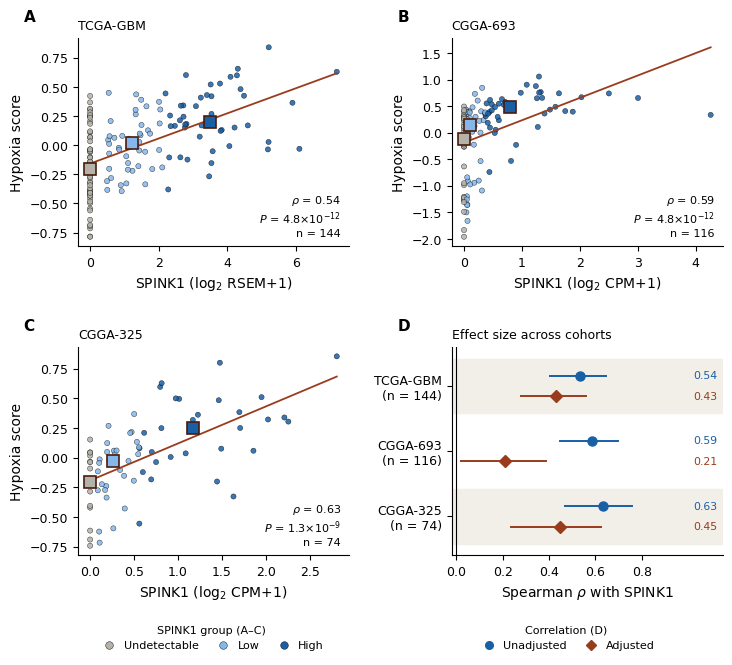

In [10]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'DejaVu Sans'],
                     'font.size': 9, 'axes.labelsize': 10, 'axes.linewidth': 0.8,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'legend.frameon': False, 'pdf.fonttype': 42})
PALETTE = {'Undetectable': '#B4B2A9', 'Low': '#85B7EB', 'High': '#185FA5'}
STYLE = {'Unadjusted': ('#185FA5', 'o', 0.16), 'Adjusted': ('#993C1D', 'D', -0.16)}

def p_label(p):
    m, e = f'{p:.1e}'.split('e')
    return f'$P$ = {m}$\\times$10$^{{{int(e)}}}$'

fig, axes = plt.subplots(2, 2, figsize=(7.4, 6.2))

for a, (name, (d, unit)) in zip(axes.flat[:3], SETS.items()):
    a.scatter(d['SPINK1'], d['Hypoxia'], s=14, c=d['group'].map(PALETTE),
              edgecolors='black', linewidths=0.3, alpha=0.85, zorder=2)
    slope, intercept = np.polyfit(d['SPINK1'], d['Hypoxia'], 1)
    xs = np.linspace(d['SPINK1'].min(), d['SPINK1'].max(), 50)
    a.plot(xs, slope * xs + intercept, color='#993C1D', lw=1.3, zorder=3)
    for g in GROUP_ORDER:
        m = d[d['group'] == g]
        a.plot(m['SPINK1'].median(), m['Hypoxia'].median(), marker='s', ms=8,
               color=PALETTE[g], mec='#4A1B0C', mew=1.2, zorder=4)
    r, p = spearmanr(d['SPINK1'], d['Hypoxia'])
    a.text(0.97, 0.04, f'$\\rho$ = {r:.2f}\n{p_label(p)}\nn = {len(d)}', transform=a.transAxes,
           ha='right', va='bottom', fontsize=8)
    a.set_title(name, loc='left', fontsize=9)
    a.set_xlabel(f'SPINK1 ({unit})')
    a.set_ylabel('Hypoxia score')

ax = axes[1, 1]
names = list(SETS)
ypos = {c: len(names) - 1 - i for i, c in enumerate(names)}
for c in names[::2]:
    ax.axhspan(ypos[c] - 0.42, ypos[c] + 0.42, color='#F1EFE8', zorder=0)
for _, r in effects.iterrows():
    color, marker, offset = STYLE[r['series']]
    y = ypos[r['cohort']] + offset
    ax.plot([r['CI_low'], r['CI_high']], [y, y], color=color, lw=1.4, zorder=2)
    ax.plot(r['rho'], y, marker=marker, ms=6.5, color=color, zorder=3)
    ax.text(1.02, y, f"{r['rho']:.2f}", va='center', fontsize=7.8, color=color)
ax.axvline(0, color='black', lw=0.8, zorder=1)
ax.set_yticks(list(ypos.values()))
ax.set_yticklabels([f'{c}\n(n = {len(SETS[c][0])})' for c in names])
ax.set_ylim(-0.6, 2.6)
ax.set_xlim(-0.02, 1.15)
ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8])
ax.set_xlabel('Spearman $\\rho$ with SPINK1')
ax.set_title('Effect size across cohorts', loc='left', fontsize=9)

for a, label in zip(axes.flat, 'ABCD'):
    a.text(-0.2, 1.08, label, transform=a.transAxes, fontsize=11, fontweight='bold')
fig.tight_layout(h_pad=2.0, w_pad=2.0)

group_handles = [Line2D([], [], marker='o', ls='', mfc=PALETTE[g], mec='black', mew=0.3, ms=5.5, label=g)
                 for g in GROUP_ORDER]
series_handles = [Line2D([], [], marker=STYLE[s][1], ls='', color=STYLE[s][0], ms=5.5, label=s)
                  for s in STYLE]
fig.legend(handles=group_handles, title='SPINK1 group (A–C)', loc='upper center', ncol=3,
           bbox_to_anchor=(0.29, 0.0), fontsize=8, title_fontsize=8, columnspacing=1.2, handletextpad=0.3)
fig.legend(handles=series_handles, title='Correlation (D)', loc='upper center', ncol=2,
           bbox_to_anchor=(0.77, 0.0), fontsize=8, title_fontsize=8, columnspacing=1.2, handletextpad=0.3)

for ext in ['png', 'pdf']:
    fig.savefig(os.path.join(RESULTS, f'Figure_4_hypoxia_replication.{ext}'), dpi=600, bbox_inches='tight')
plt.show()